# Task 26 - Model Evaluation: RMSE / MAE / R2 with k-fold CV, Residual Plots and Heteroscedasticity

**Goal:** evaluate the Task 25 linear model with RMSE, MAE and R2 using k-fold cross-validation, analyse residual plots for error patterns, and detect (and treat) heteroscedasticity.

**Target:** `log_revenue = log1p(price x units_sold)` (there is no `yearly amount spent` column; see Task 25). Metrics are reported on the **log scale** (the modelled scale) and **back-transformed to revenue** with Duan's smearing factor, so errors can be read in currency-like units.

**Evaluation design:** 5-fold and 10-fold CV, each repeated 5 times; train vs test gaps; out-of-fold (OOF) predictions for diagnostics so residuals are never in-sample.

**Diagnostics:** residual vs fitted, Q-Q, histogram, scale-location, residual vs top features, leverage / Cook's distance; **Breusch-Pagan, White, Goldfeld-Quandt**, Spearman |residual| vs fitted, Levene across fitted deciles; Shapiro-Wilk and Jarque-Bera for normality.
**Remedies tested:** HC3 robust standard errors and weighted least squares (WLS).

**Input:** `data/processed/womens_clothing_regression_dataset.csv` and `reports/task_25_selected_features.csv` (run Task 25 first)
**Outputs:** `data/processed/womens_clothing_regression_predictions.csv`, `reports/task_26_cv_metrics.csv`, `reports/task_26_residual_diagnostics.csv`, `reports/task_26_error_by_decile.csv`, `reports/task_26_coefficients_ols_hc3.csv`, `reports/task_26_analysis_status.csv`

In [1]:
import re, warnings
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

def find_project_root():
    """Walk up from the notebook folder until a folder containing data/processed is found."""
    start = Path.cwd().resolve()
    for cand in [start, *start.parents]:
        if (cand / "data" / "processed").exists():
            return cand
    return start.parent

ROOT = find_project_root()
PROC, REPORTS = ROOT / "data" / "processed", ROOT / "reports"
RAW = ROOT / "data" / "raw" / "womens_clothing.csv"
PROC.mkdir(parents=True, exist_ok=True); REPORTS.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

def _norm(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())

def pick(df, *candidates, required=True):
    """Return the real column name matching any candidate (ignores case, spaces, underscores)."""
    lookup = {_norm(c): c for c in df.columns}
    for cand in candidates:
        if _norm(cand) in lookup:
            return lookup[_norm(cand)]
    if required:
        raise KeyError(f"None of {candidates} found. Columns: {list(df.columns)}")
    return None

def load_first(*paths):
    """Load the first existing CSV, so each task builds on the newest previous output."""
    for p in paths:
        if Path(p).exists():
            d = pd.read_csv(p)
            d = d.loc[:, ~d.columns.str.startswith("Unnamed")]
            print(f"Loaded: {Path(p).name}  shape={d.shape}")
            return d, Path(p)
    raise FileNotFoundError("None of these files exist: " + ", ".join(str(p) for p in paths))

def add_from_raw(df, *names):
    """Borrow columns missing from df (e.g. title, tags) from data/raw, matched on product_id."""
    missing = [n for n in names if pick(df, n, required=False) is None]
    if not missing:
        return df
    raw = pd.read_csv(RAW); raw = raw.loc[:, ~raw.columns.str.startswith("Unnamed")]
    kd, kr = pick(df, "product_id", required=False), pick(raw, "product_id", required=False)
    if kd is None or kr is None:
        raise KeyError(f"Need product_id in both files to borrow {missing} from raw")
    got = [pick(raw, n) for n in missing if pick(raw, n, required=False)]
    if not got:
        raise KeyError(f"{missing} not found in raw file either")
    add = raw.drop_duplicates(kr)[[kr] + got].rename(columns={kr: kd})
    out = df.merge(add, on=kd, how="left")
    print("Borrowed from raw:", got)
    return out

# Newest cumulative dataset first; each task reads the newest file produced BEFORE it.
CHAIN = ["womens_clothing_high_cardinality_encoded.csv", "womens_clothing_engagement_features.csv",
         "womens_clothing_sentiment_features.csv", "womens_clothing_age_segmented.csv",
         "womens_clothing_review_text_features.csv", "womens_clothing_market_basket_features.csv",
         "womens_clothing_product_text_features.csv", "womens_clothing_product_tag_features.csv",
         "womens_clothing_product_segmented.csv", "womens_clothing_final.csv"]

# Tasks 19-21 outputs sit in front of the older chain.
LATE = ["womens_clothing_lifecycle_features.csv", "womens_clothing_tfidf_features.csv", "womens_clothing_channel_interaction_features.csv"]
FULL = LATE + CHAIN

# Tasks 22-24 outputs sit in front of everything.
LATE2 = ["womens_clothing_rating_sentiment_encoded.csv", "womens_clothing_pca_features.csv"]
ALL = LATE2 + FULL

REG_DATASET = "womens_clothing_regression_dataset.csv"      # written by Task 25, read by Tasks 26-27

import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan, het_white, het_goldfeldquandt
from statsmodels.stats.stattools import jarque_bera
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, RepeatedKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
sns.set_theme(style="whitegrid"); pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42; TARGET_NAME = "log_revenue"; ALPHA = 0.05

Project root: D:\OneDrive\Desktop\Brainybeams\Womens_Clothing_ML_Project


## 1. Load the Task 25 dataset and the final feature list

In [2]:
reg = pd.read_csv(PROC / "womens_clothing_regression_dataset.csv")
ft = pd.read_csv(REPORTS / "task_25_selected_features.csv")
features = list(ft.loc[ft["selected"] | ft["interaction_kept"], "feature"])
id_col = pick(reg, "product_id", required=False)
y = reg[TARGET_NAME]; X = reg[features]
print(f"{len(reg):,} products | {len(features)} features: {features}")

1,539 products | 25 features: ['merchant_rating_count', 'product_variation_inventory', 'price', 'pca_cat_5', 'shipping_option_price', 'merchant_rating', 'svd_product_variation_size_id_2', 'svd_product_variation_size_id_1', 'pca_cat_21', 'svd_product_variation_size_id_3', 'txt_word_count', 'svd_product_variation_size_id_4', 'txt_char_count', 'txt_title_word_count', 'pca_cat_4', 'merchant_has_profile_picture', 'badge_product_quality', 'pca_cat_3', 'pca_cat_14', 'pca_cat_17', 'ix__price__txt_char_count', 'ix__product_variation_inventory__pca_cat_21', 'sq__merchant_rating_count', 'sq__txt_word_count', 'sq__price']


## 2. k-fold cross-validation (RMSE, MAE, R2)

In [3]:
def metrics(yt, yp, smear=None):
    out = {"rmse": mean_squared_error(yt, yp) ** .5, "mae": mean_absolute_error(yt, yp), "r2": r2_score(yt, yp)}
    return out

def run_cv(k, repeats):
    rows = []
    for i, (tr, te) in enumerate(RepeatedKFold(n_splits=k, n_repeats=repeats, random_state=RANDOM_STATE).split(X)):
        sc_m, sc_s = X.iloc[tr].mean(), X.iloc[tr].std().replace(0, 1)
        m = LinearRegression().fit((X.iloc[tr] - sc_m) / sc_s, y.iloc[tr])
        ptr, pte = m.predict((X.iloc[tr] - sc_m) / sc_s), m.predict((X.iloc[te] - sc_m) / sc_s)
        smear = np.mean(np.exp(y.iloc[tr].values - ptr))                           # Duan smearing on the training fold
        rev_hat = np.expm1(pte + np.log(smear)).clip(min=0); rev = np.expm1(y.iloc[te])
        te_m, tr_m = metrics(y.iloc[te], pte), metrics(y.iloc[tr], ptr)
        rows.append({"k": k, "repeat": i // k, "fold": i % k, "test_rmse": te_m["rmse"], "test_mae": te_m["mae"], "test_r2": te_m["r2"],
                     "train_rmse": tr_m["rmse"], "train_r2": tr_m["r2"], "test_rmse_revenue": mean_squared_error(rev, rev_hat) ** .5,
                     "test_mae_revenue": mean_absolute_error(rev, rev_hat), "test_median_abs_err_revenue": np.median(np.abs(rev - rev_hat))})
    return pd.DataFrame(rows)
cv_all = pd.concat([run_cv(5, 5), run_cv(10, 5)], ignore_index=True)
summary = cv_all.groupby("k").agg(["mean", "std"]).drop(columns=["repeat", "fold"], level=0)
summary.columns = ["_".join(c) for c in summary.columns]; summary.round(4).T

k,5,10
test_rmse_mean,1.7775,1.7747
test_rmse_std,0.0490,0.0831
test_mae_mean,1.4622,1.4608
test_mae_std,0.0419,0.0686
test_r2_mean,0.3360,0.3345
test_r2_std,0.0330,0.0640
train_rmse_mean,1.7439,1.7458
train_rmse_std,0.0123,0.0092
train_r2_mean,0.3634,0.3621
train_r2_std,0.0083,0.0067


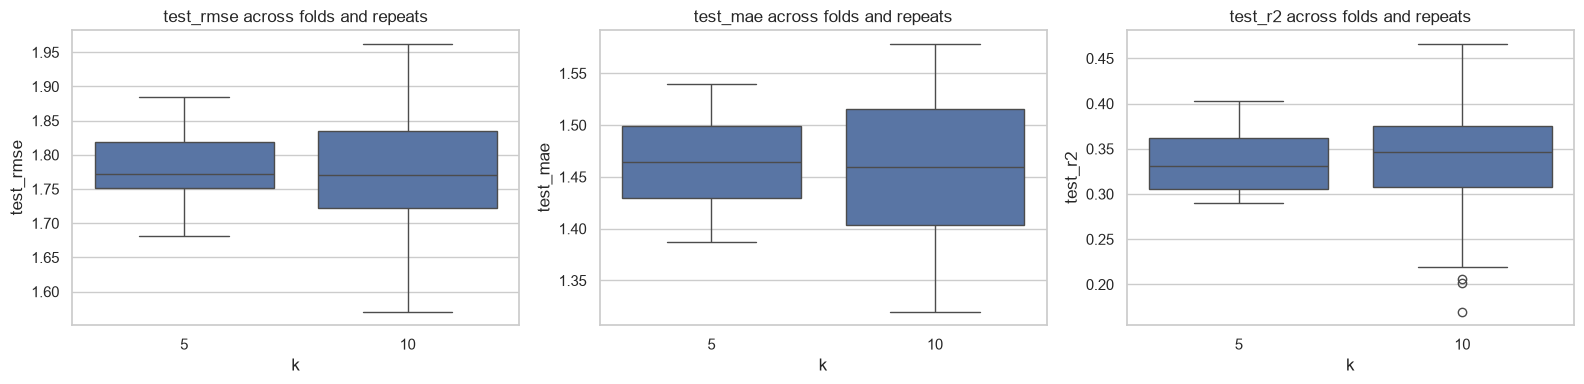

,train_r2,test_r2,gap
k,,,
5,0.3634,0.3360,0.0273
10,0.3621,0.3345,0.0276


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, m in zip(ax, ["test_rmse", "test_mae", "test_r2"]): sns.boxplot(data=cv_all, x="k", y=m, ax=a, color="#4c72b0"); a.set_title(f"{m} across folds and repeats")
plt.tight_layout(); plt.show()
gap = (cv_all.groupby("k")[["train_r2", "test_r2"]].mean().assign(gap=lambda d: d["train_r2"] - d["test_r2"])).round(4); gap

## 3. Out-of-fold residuals

In [5]:
kf = KFold(10, shuffle=True, random_state=RANDOM_STATE); oof = np.zeros(len(y))
for tr, te in kf.split(X):
    mu, sd = X.iloc[tr].mean(), X.iloc[tr].std().replace(0, 1)
    oof[te] = LinearRegression().fit((X.iloc[tr] - mu) / sd, y.iloc[tr]).predict((X.iloc[te] - mu) / sd)
resid = y.values - oof
Xs = (X - X.mean()) / X.std().replace(0, 1); full = sm.OLS(y, sm.add_constant(Xs)).fit()
infl = full.get_influence(); std_resid = pd.Series(resid / resid.std(), index=y.index)
print(f"OOF RMSE {np.sqrt(np.mean(resid ** 2)):.4f} | MAE {np.mean(np.abs(resid)):.4f} | R2 {r2_score(y, oof):.4f} | mean residual {resid.mean():+.4f}")

OOF RMSE 1.7748 | MAE 1.4593 | R2 0.3407 | mean residual -0.0023


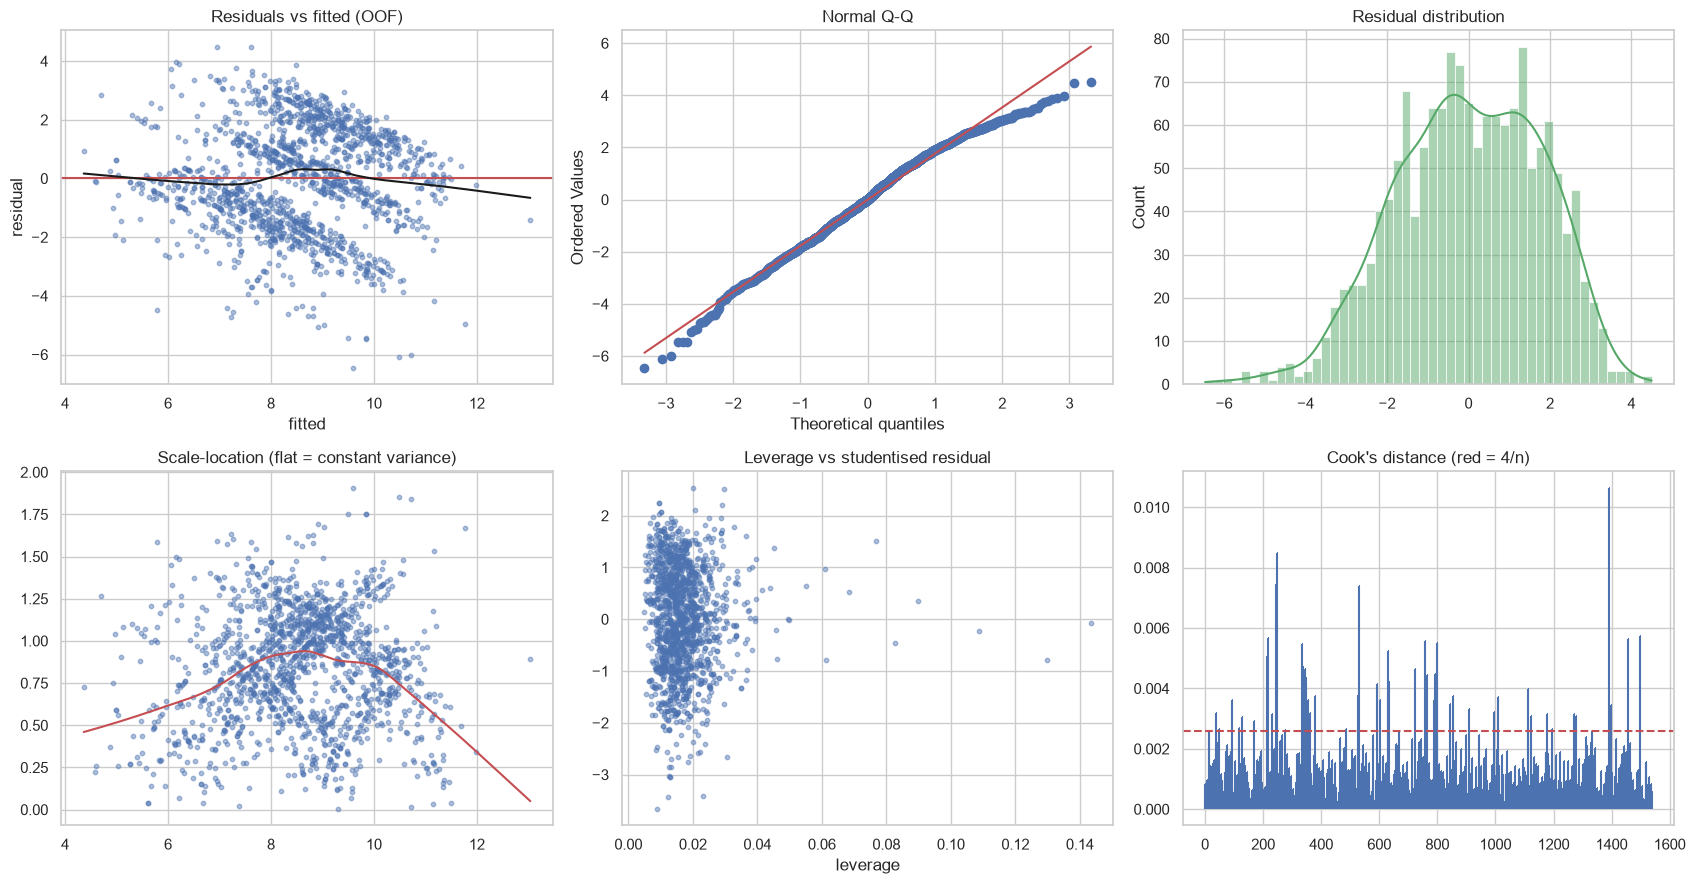

In [6]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
ax[0, 0].scatter(oof, resid, s=10, alpha=.45); ax[0, 0].axhline(0, color="r"); ax[0, 0].set_title("Residuals vs fitted (OOF)"); ax[0, 0].set_xlabel("fitted"); ax[0, 0].set_ylabel("residual")
lw = sm.nonparametric.lowess(resid, oof, frac=.4); ax[0, 0].plot(lw[:, 0], lw[:, 1], color="k")
stats.probplot(resid, dist="norm", plot=ax[0, 1]); ax[0, 1].set_title("Normal Q-Q")
sns.histplot(resid, bins=50, kde=True, ax=ax[0, 2], color="#55a868"); ax[0, 2].set_title("Residual distribution")
ax[1, 0].scatter(oof, np.sqrt(np.abs(std_resid)), s=10, alpha=.45); lw = sm.nonparametric.lowess(np.sqrt(np.abs(std_resid)), oof, frac=.4); ax[1, 0].plot(lw[:, 0], lw[:, 1], color="r"); ax[1, 0].set_title("Scale-location (flat = constant variance)")
ax[1, 1].scatter(infl.hat_matrix_diag, infl.resid_studentized_internal, s=10, alpha=.45); ax[1, 1].set_title("Leverage vs studentised residual"); ax[1, 1].set_xlabel("leverage")
ax[1, 2].stem(np.arange(len(y)), infl.cooks_distance[0], markerfmt=",", basefmt=" "); ax[1, 2].axhline(4 / len(y), color="r", ls="--"); ax[1, 2].set_title("Cook's distance (red = 4/n)")
plt.tight_layout(); plt.show()

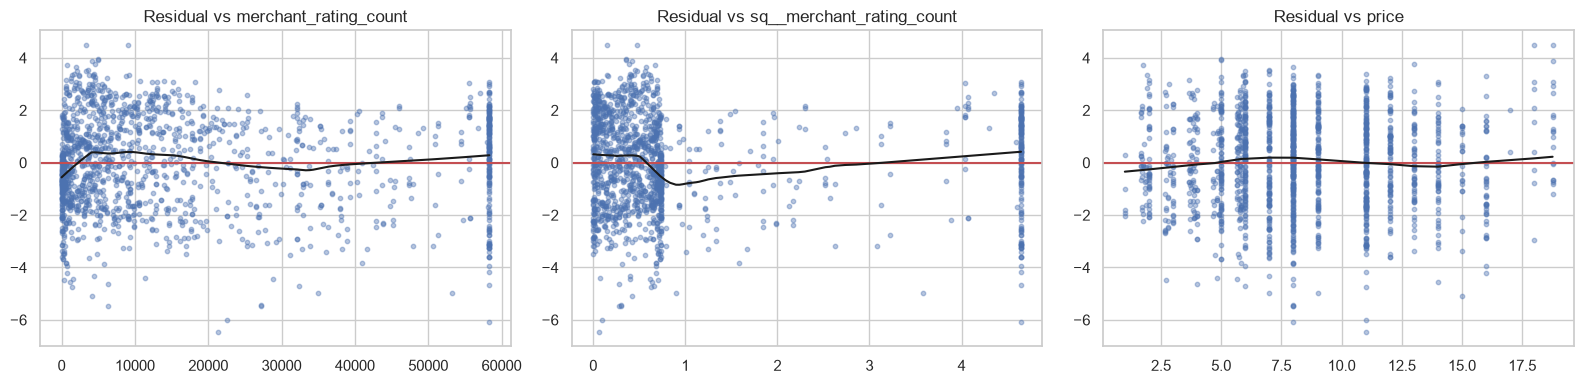

In [7]:
top = full.params.drop("const").abs().sort_values(ascending=False).index[:3]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, f in zip(ax, top):
    a.scatter(X[f], resid, s=10, alpha=.4); a.axhline(0, color="r"); lw = sm.nonparametric.lowess(resid, X[f], frac=.5); a.plot(lw[:, 0], lw[:, 1], color="k"); a.set_title(f"Residual vs {f}")
plt.tight_layout(); plt.show()

## 4. Heteroscedasticity and normality tests

Null hypothesis of Breusch-Pagan / White / Goldfeld-Quandt: **constant error variance**. A small p-value (< 0.05) indicates heteroscedasticity. Tests use the in-sample OLS residuals (the standard setting for these tests); the OOF residuals are used for the visual checks and the decile table.

In [8]:
ex = sm.add_constant(Xs); rows = []
bp = het_breuschpagan(full.resid, ex); rows.append(("Breusch-Pagan (Koenker)", bp[0], bp[1], "variance depends linearly on features"))
try: wh = het_white(full.resid, ex); rows.append(("White", wh[0], wh[1], "general form (squares + cross terms)"))
except Exception as e: rows.append(("White", np.nan, np.nan, "skipped: " + str(e)[:60]))
order_f = np.argsort(full.fittedvalues.values); gq = het_goldfeldquandt(y.values[order_f], ex.values[order_f], alternative="two-sided"); rows.append(("Goldfeld-Quandt (sorted by fitted)", gq[0], gq[1], "variance differs between low and high fitted values"))
rho, p_rho = stats.spearmanr(np.abs(resid), oof); rows.append(("Spearman |resid| vs fitted", rho, p_rho, "monotone variance trend"))
dec = pd.qcut(pd.Series(oof).rank(method="first"), 10, labels=False); lev = stats.levene(*[resid[dec == d] for d in range(10)]); rows.append(("Levene across fitted deciles", lev[0], lev[1], "equal variance across deciles"))
sh = stats.shapiro(resid); rows.append(("Shapiro-Wilk (normal residuals)", sh[0], sh[1], "normality"))
jb = jarque_bera(resid); rows.append(("Jarque-Bera (normal residuals)", jb[0], jb[1], "skew + kurtosis normality"))
diag = pd.DataFrame(rows, columns=["test", "statistic", "p_value", "tests_for"]); diag["reject_at_5pct"] = diag["p_value"] < ALPHA
diag["skew"] = stats.skew(resid); diag["excess_kurtosis"] = stats.kurtosis(resid); diag.round(5)

d:\OneDrive\Desktop\Brainybeams\Womens_Clothing_ML_Project\.venv\Lib\site-packages\statsmodels\stats\diagnostic.py:1272: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  resols = OLS(y**2, exog).fit()


,test,statistic,p_value,tests_for,reject_at_5pct,skew,excess_kurtosis
0,Breusch-Pagan (Koenker),63.45934,0.00003,variance depends linearly on features,True,-0.27992,-0.28163
1,White,408.63632,0.00324,general form (squares + cross terms),True,-0.27992,-0.28163
2,Goldfeld-Quandt (sorted by fitted),1.11266,0.14580,variance differs between low and high fitted v...,False,-0.27992,-0.28163
3,Spearman |resid| vs fitted,0.04321,0.09013,monotone variance trend,False,-0.27992,-0.28163
4,Levene across fitted deciles,8.25112,0.00000,equal variance across deciles,True,-0.27992,-0.28163
5,Shapiro-Wilk (normal residuals),0.98976,0.00000,normality,True,-0.27992,-0.28163
6,Jarque-Bera (normal residuals),25.18400,0.00000,skew + kurtosis normality,True,-0.27992,-0.28163


Largest / smallest residual SD across fitted deciles: 1.45x  (about 1 = constant variance; > 2 = clear heteroscedasticity)


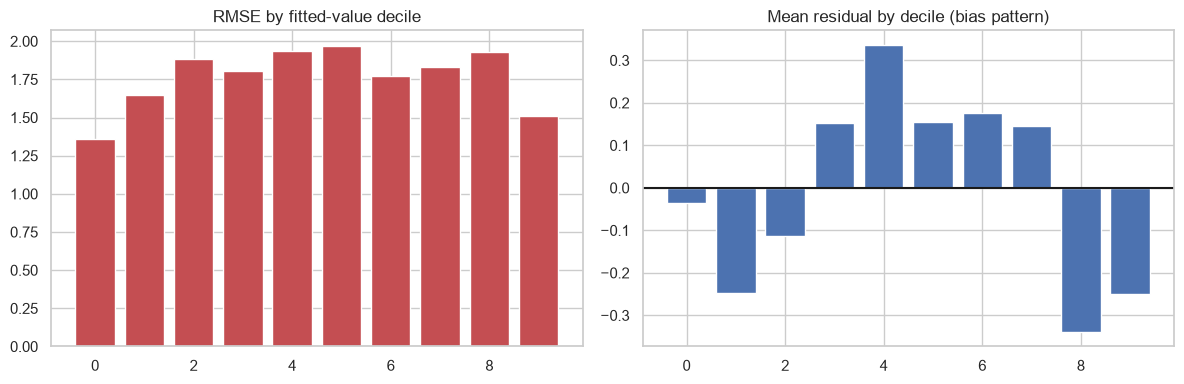

,decile,n,mean_fitted,mean_resid,rmse,mae,resid_sd
0,0,154,6.0968,-0.0354,1.3591,0.9581,1.3631
1,1,154,7.1868,-0.2469,1.6495,1.3150,1.6362
2,2,154,7.7234,-0.1131,1.8810,1.6013,1.8837
3,3,154,8.1225,0.1522,1.8068,1.5988,1.8062
4,4,154,8.4456,0.3364,1.9349,1.6871,1.9117
5,5,153,8.7620,0.1557,1.9717,1.7232,1.9720
6,6,154,9.0860,0.1750,1.7739,1.4696,1.7710
7,7,154,9.4596,0.1443,1.8280,1.5073,1.8283
8,8,154,9.9505,-0.3395,1.9304,1.6206,1.9065
9,9,154,10.7345,-0.2503,1.5124,1.1141,1.4964


In [9]:
by_dec = pd.DataFrame({"decile": dec, "fitted": oof, "resid": resid, "abs_resid": np.abs(resid)}).groupby("decile").agg(
    n=("resid", "size"), mean_fitted=("fitted", "mean"), mean_resid=("resid", "mean"), rmse=("resid", lambda r: np.sqrt(np.mean(r ** 2))), mae=("abs_resid", "mean"), resid_sd=("resid", "std")).reset_index()
ratio = by_dec["resid_sd"].max() / by_dec["resid_sd"].min(); print(f"Largest / smallest residual SD across fitted deciles: {ratio:.2f}x  (about 1 = constant variance; > 2 = clear heteroscedasticity)")
fig, ax = plt.subplots(1, 2, figsize=(12, 4)); ax[0].bar(by_dec["decile"], by_dec["rmse"], color="#c44e52"); ax[0].set_title("RMSE by fitted-value decile"); ax[1].bar(by_dec["decile"], by_dec["mean_resid"], color="#4c72b0"); ax[1].axhline(0, color="k"); ax[1].set_title("Mean residual by decile (bias pattern)")
plt.tight_layout(); plt.show(); by_dec.round(4)

In [10]:
n_infl = int((infl.cooks_distance[0] > 4 / len(y)).sum()); n_out = int((np.abs(infl.resid_studentized_internal) > 3).sum())
print(f"Influential points (Cook's D > 4/n): {n_infl} | outliers (|studentised resid| > 3): {n_out} | max leverage {infl.hat_matrix_diag.max():.3f}")
hetero = bool(diag.loc[diag["test"].str.startswith(("Breusch", "White", "Goldfeld")), "reject_at_5pct"].any())
print("Heteroscedasticity detected by at least one formal test:", hetero)

Influential points (Cook's D > 4/n): 51 | outliers (|studentised resid| > 3): 6 | max leverage 0.143
Heteroscedasticity detected by at least one formal test: True


## 5. Remedies

1. **HC3 robust standard errors** keep the coefficients but correct the standard errors, so p-values and confidence intervals stay valid under heteroscedasticity.
2. **Weighted least squares:** model log(residual^2) on the fitted values, use `1 / predicted variance` as weights, and refit. WLS improves efficiency and inference; it need not lower RMSE, so its CV error is shown only for completeness.

In [11]:
hc3 = sm.OLS(y, ex).fit(cov_type="HC3")
coef = pd.DataFrame({"coef_standardised": full.params, "se_ols": full.bse, "se_hc3": hc3.bse, "p_ols": full.pvalues, "p_hc3": hc3.pvalues}).drop("const")
coef["se_ratio_hc3_over_ols"] = coef["se_hc3"] / coef["se_ols"]; coef["significance_changes"] = (coef["p_ols"] < ALPHA) != (coef["p_hc3"] < ALPHA)
print("Features whose significance changes under HC3:", list(coef.index[coef["significance_changes"]]) or "none"); coef.sort_values("p_hc3").round(5)

Features whose significance changes under HC3: none


,coef_standardised,se_ols,se_hc3,p_ols,p_hc3,se_ratio_hc3_over_ols,significance_changes
merchant_rating_count,1.02569,0.09041,0.09250,0.00000,0.00000,1.02312,False
sq__price,-0.35598,0.05055,0.05199,0.00000,0.00000,1.02850,False
sq__merchant_rating_count,-0.57874,0.08626,0.08932,0.00000,0.00000,1.03539,False
price,0.53562,0.09492,0.09499,0.00000,0.00000,1.00077,False
pca_cat_21,-0.24099,0.04689,0.04504,0.00000,0.00000,0.96038,False
product_variation_inventory,0.22360,0.05328,0.05482,0.00003,0.00005,1.02877,False
badge_product_quality,0.15501,0.04643,0.03969,0.00086,0.00009,0.85498,False
pca_cat_14,-0.17958,0.05030,0.04833,0.00037,0.00020,0.96079,False
merchant_rating,0.15938,0.04874,0.04387,0.00110,0.00028,0.89998,False
pca_cat_3,-0.18471,0.05216,0.05127,0.00041,0.00031,0.98292,False


In [12]:
# WLS two-step, evaluated with the same 10-fold split
oof_w = np.zeros(len(y))
for tr, te in kf.split(X):
    mu, sd = X.iloc[tr].mean(), X.iloc[tr].std().replace(0, 1); Atr, Ate = sm.add_constant((X.iloc[tr] - mu) / sd), sm.add_constant((X.iloc[te] - mu) / sd, has_constant="add")
    ols_ = sm.OLS(y.iloc[tr], Atr).fit(); vf = sm.OLS(np.log(ols_.resid ** 2 + 1e-8), sm.add_constant(ols_.fittedvalues)).fit()
    w = 1 / np.exp(vf.predict(sm.add_constant(ols_.fittedvalues))); oof_w[te] = sm.WLS(y.iloc[tr], Atr, weights=w).fit().predict(Ate)
cmp = pd.DataFrame({"OLS": metrics(y, oof), "WLS": metrics(y, oof_w)}).T; cmp.round(4)

,rmse,mae,r2
OLS,1.7748,1.4593,0.3407
WLS,1.7755,1.4591,0.3402


## 6. Save outputs

In [13]:
pred = pd.DataFrame({TARGET_NAME: y, "oof_prediction": oof, "residual": resid, "std_residual": std_resid, "fitted_decile": dec.values, "cooks_distance": infl.cooks_distance[0],
                     "leverage": infl.hat_matrix_diag, "revenue_actual": np.expm1(y), "revenue_pred": np.expm1(oof + np.log(np.mean(np.exp(y.values - oof))))})
if id_col: pred.insert(0, id_col, reg[id_col].values)
pred_path = PROC / "womens_clothing_regression_predictions.csv"; pred.to_csv(pred_path, index=False)
cv_all.round(6).to_csv(REPORTS / "task_26_cv_metrics.csv", index=False)
diag.round(6).to_csv(REPORTS / "task_26_residual_diagnostics.csv", index=False); by_dec.round(6).to_csv(REPORTS / "task_26_error_by_decile.csv", index=False)
coef.round(6).reset_index(names="feature").to_csv(REPORTS / "task_26_coefficients_ols_hc3.csv", index=False)
m5 = cv_all[cv_all["k"] == 5]
status = pd.DataFrame([{"task": "Task 26 - Regression evaluation and residual analysis", "status": "completed", "run_at": datetime.now().isoformat(timespec="seconds"),
    "rows": len(reg), "n_features": len(features), "cv5_rmse": round(m5["test_rmse"].mean(), 4), "cv5_mae": round(m5["test_mae"].mean(), 4), "cv5_r2": round(m5["test_r2"].mean(), 4),
    "cv10_r2": round(cv_all[cv_all["k"] == 10]["test_r2"].mean(), 4), "heteroscedasticity_detected": hetero, "resid_sd_ratio_max_min": round(ratio, 2),
    "influential_points": n_infl, "outliers_gt3": n_out, "residuals_normal_shapiro_p": round(float(sh[1]), 5), "output_dataset": pred_path.name}])
status.to_csv(REPORTS / "task_26_analysis_status.csv", index=False); status.T

,0
task,Task 26 - Regression evaluation and residual a...
status,completed
run_at,2026-11-26T15:51:44
rows,1539
n_features,25
cv5_rmse,1.7775
cv5_mae,1.4622
cv5_r2,0.336
cv10_r2,0.3345
heteroscedasticity_detected,True
